# Performing DEG Pathway analysis (limma, R) on Pseudobulked classcial DC2 data from atlas
* Ovarian cancer samples only
* dataframes made previously (2026-04-10_PseudobulkingSampleType_fromNRcode.jpynb), separate for the SIK3 DC2 subset and each has seperate metadata file
* Using modified code from ChatGPT -27/10/26
* 28/10/26

* Use R_env

In [1]:
library(limma)
library(edgeR)
library(dplyr)
library(RColorBrewer)
library(Seurat)
library(ggplot2)
library(pheatmap)
library(ggrepel)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built with package ‘Matrix’ 1.7.4 but the current
version is 1.7.5; it is recomended that you reinstall ‘SeuratObject’ as
the ABI for ‘Matrix’ may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t




In [2]:
#set directory
setwd("/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/NewDC2subsets_Analysis/DC2_Pseudobulk/")

In [3]:
list.files()

[1] "pseudobulk_dc2_data.csv"      "pseudobulk_dc3_data.csv"     
 [3] "pseudobulk_IL18_data.csv"     "pseudobulk_ISG_data.csv"     
 [5] "pseudobulk_metadata_dc2.csv"  "pseudobulk_metadata_dc3.csv" 
 [7] "pseudobulk_metadata_IL18.csv" "pseudobulk_metadata_ISG.csv" 
 [9] "pseudobulk_metadata_SIK3.csv" "pseudobulk_SIK3_data.csv"

## Read in Pseudobulked data 

In [4]:

#read in csv files for pseudobulked data
#read only the 5 DC2 subsets with more than 20 cells per condition(primary vs metastatic)
pseudobulk_dc2 <- read.csv("pseudobulk_dc2_data.csv", row.names = 1, check.names = F)


In [5]:
#read in csv files for metadata
dc2_metadata <- read.csv("pseudobulk_metadata_dc2.csv")


# Prepare and check the data

In [6]:
#Inspect data
dim(pseudobulk_dc2)
dim(dc2_metadata)

[1] 15074   102

[1] 102   2

In [7]:
#Inspect the data
head(pseudobulk_dc2)
head(dc2_metadata)

,GSE180661_SPECTRUM-OV-002_S1_CD45P_RIGHT_OVARY,GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_ADNEXA,GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_UPPER_QUADRANT,GSE180661_SPECTRUM-OV-008_S1_CD45P_INFRACOLIC_OMENTUM,GSE180661_SPECTRUM-OV-009_S1_CD45P_BOWEL,GSE180661_SPECTRUM-OV-009_S1_CD45P_INFRACOLIC_OMENTUM,GSE180661_SPECTRUM-OV-009_S1_CD45P_LEFT_UPPER_QUADRANT,GSE180661_SPECTRUM-OV-009_S1_CD45P_PELVIC_PERITONEUM,GSE180661_SPECTRUM-OV-009_S1_CD45P_RIGHT_UPPER_QUADRANT,GSE180661_SPECTRUM-OV-014_S1_CD45P_BOWEL,⋯,GSE217517_HGSOC_pt8,PRJCA005422_HGSOC1_MT,PRJCA005422_HGSOC1_PT,PRJCA005422_HGSOC2_PT,PRJCA005422_HGSOC3_MT,PRJCA005422_HGSOC3_PT,PRJCA005422_HGSOC4_MT,PRJCA005422_HGSOC4_PT,PRJCA005422_HGSOC6_MT,PRJCA005422_HGSOC7_PT
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
FAM87B,0,0,0,0,0,0,0,1,0,0,⋯,0,0,0,0,0,0,0,0,0,0
LINC00115,1,0,1,2,0,0,0,0,1,2,⋯,0,3,1,0,0,0,1,0,0,0
FAM41C,1,0,0,3,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
SAMD11,0,0,0,1,0,0,0,0,0,0,⋯,0,0,0,0,0,1,0,0,0,1
NOC2L,5,0,2,13,6,1,6,1,6,4,⋯,2,17,11,6,2,1,7,6,3,5
KLHL17,0,0,0,0,0,0,0,0,0,1,⋯,1,0,0,0,0,0,0,0,0,0


,integration_id,sample_type_major2
,<chr>,<chr>
1,GSE180661_SPECTRUM-OV-002_S1_CD45P_RIGHT_OVARY,primary tumour
2,GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_ADNEXA,primary tumour
3,GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_UPPER_QUADRANT,metastatic tumour
4,GSE180661_SPECTRUM-OV-008_S1_CD45P_INFRACOLIC_OMENTUM,metastatic tumour
5,GSE180661_SPECTRUM-OV-009_S1_CD45P_BOWEL,metastatic tumour
6,GSE180661_SPECTRUM-OV-009_S1_CD45P_INFRACOLIC_OMENTUM,metastatic tumour


In [8]:
# Rename columns to remove the spaces
dc2_metadata <- dc2_metadata %>%
  mutate(sample_type_major2 = recode(sample_type_major2, 
         "primary tumour" = "primary_tumour", 
         "metastatic tumour" = "metastatic_tumour"))

In [9]:
head(dc2_metadata)

,integration_id,sample_type_major2
,<chr>,<chr>
1,GSE180661_SPECTRUM-OV-002_S1_CD45P_RIGHT_OVARY,primary_tumour
2,GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_ADNEXA,primary_tumour
3,GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_UPPER_QUADRANT,metastatic_tumour
4,GSE180661_SPECTRUM-OV-008_S1_CD45P_INFRACOLIC_OMENTUM,metastatic_tumour
5,GSE180661_SPECTRUM-OV-009_S1_CD45P_BOWEL,metastatic_tumour
6,GSE180661_SPECTRUM-OV-009_S1_CD45P_INFRACOLIC_OMENTUM,metastatic_tumour


In [10]:
# Check for duplicated sample IDs
stopifnot(!anyDuplicated(dc2_metadata$integration_id))

In [11]:
 # Check that metadata samples exist in the counts
stopifnot(all(dc2_metadata$integration_id %in% colnames(pseudobulk_dc2)))


In [12]:
# Reorder metadata to match the counts
dc2_metadata <- dc2_metadata[match(colnames(pseudobulk_dc2), dc2_metadata$integration_id),]


In [13]:
head(dc2_metadata)

,integration_id,sample_type_major2
,<chr>,<chr>
1,GSE180661_SPECTRUM-OV-002_S1_CD45P_RIGHT_OVARY,primary_tumour
2,GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_ADNEXA,primary_tumour
3,GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_UPPER_QUADRANT,metastatic_tumour
4,GSE180661_SPECTRUM-OV-008_S1_CD45P_INFRACOLIC_OMENTUM,metastatic_tumour
5,GSE180661_SPECTRUM-OV-009_S1_CD45P_BOWEL,metastatic_tumour
6,GSE180661_SPECTRUM-OV-009_S1_CD45P_INFRACOLIC_OMENTUM,metastatic_tumour


In [14]:
# Remove count columns not represented in metadata
pseudobulk_dc2 <- pseudobulk_dc2[ ,colnames(pseudobulk_dc2) %in% dc2_metadata$integration_id,drop = FALSE]

In [15]:
dim(pseudobulk_dc2)

[1] 15074   102

In [16]:
# Align metadata exactly to the count matrix
dc2_metadata <- dc2_metadata[match(colnames(pseudobulk_dc2), dc2_metadata$integration_id),]

In [17]:
# Set the reference condition
dc2_metadata$sample_type_major2 <- factor(dc2_metadata$sample_type_major2, levels = c("primary_tumour", "metastatic_tumour"))

In [18]:
# Check sample numbers
table(dc2_metadata$sample_type_major2)


   primary_tumour metastatic_tumour 
               46                56 

In [19]:
# Check alignment
stopifnot(identical(colnames(pseudobulk_dc2), dc2_metadata$integration_id))

# Perform differential gene expression analysis

In [20]:
# Convert to a numeric matrix
counts <- as.matrix(pseudobulk_dc2)
metadata <- dc2_metadata

storage.mode(counts) <- "numeric"

# Check counts are valid raw counts
stopifnot(all(is.finite(counts)))
stopifnot(all(counts >= 0))
stopifnot(all(counts == round(counts)))

In [21]:
#set the metadata levels explicitly and use the primary as the reference
metadata$sample_type_major2 <- factor( metadata$sample_type_major2, levels = c("primary_tumour", "metastatic_tumour"))

design <- model.matrix(~ sample_type_major2, data = metadata)

colnames(design)

[1] "(Intercept)"                         "sample_type_major2metastatic_tumour"

In [22]:
colnames(design)

[1] "(Intercept)"                         "sample_type_major2metastatic_tumour"

In [23]:
# Create the edgeR object
y <- DGEList(counts = counts)

# Remove genes with insufficient expression
keep <- filterByExpr(y, group = dc2_metadata$sample_type_major2)

y <- y[keep, , keep.lib.sizes = FALSE]

# Normalise library sizes using TMM
y <- calcNormFactors(y, method = "TMM")


In [24]:
y <- estimateDisp(y, design)

fit <- glmQLFit(y, design, robust = TRUE)


In [25]:
# Inspect coefficient names before testing
colnames(design)

# Test Metastatic versus Primary
qlf <- glmQLFTest( fit, coef = "sample_type_major2metastatic_tumour")

results <- topTags(qlf, n = Inf)$table

head(results)

[1] "(Intercept)"                         "sample_type_major2metastatic_tumour"

,logFC,logCPM,F,PValue,FDR
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
RPL36A,-1.3464336,8.680838,34.62263,4.883216e-08,0.0000830635
MT2A,-2.0389419,10.268845,26.67140,1.205470e-06,0.0006989210
RPL17,-1.8051528,8.527969,26.58257,1.232665e-06,0.0006989210
EIF4A1,-0.8049879,7.848377,22.52201,6.385111e-06,0.0027152684
HIST1H4C,-0.9431153,7.628867,21.09313,1.201151e-05,0.0040863147
ID2,-0.8509285,8.339792,20.37208,1.648416e-05,0.0046732600


In [26]:
library(tidyverse)

── Attaching core tidyverse packages ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ lubridate 1.9.5     ✔ tibble    3.3.1
✔ purrr     1.2.1     ✔ tidyr     1.3.2
✔ readr     2.2.0     
── Conflicts ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [27]:
#set rownames as a column called Genes
results <- rownames_to_column(results, var = "Genes")

In [28]:
head(results)

,Genes,logFC,logCPM,F,PValue,FDR
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,RPL36A,-1.3464336,8.680838,34.62263,4.883216e-08,0.0000830635
2,MT2A,-2.0389419,10.268845,26.67140,1.205470e-06,0.0006989210
3,RPL17,-1.8051528,8.527969,26.58257,1.232665e-06,0.0006989210
4,EIF4A1,-0.8049879,7.848377,22.52201,6.385111e-06,0.0027152684
5,HIST1H4C,-0.9431153,7.628867,21.09313,1.201151e-05,0.0040863147
6,ID2,-0.8509285,8.339792,20.37208,1.648416e-05,0.0046732600


In [29]:
# Define significance thresholds
fdr_cutoff <- 0.05
logfc_cutoff <- 0.58

# Classify genes
results <- results %>%
  mutate(DEG_status = case_when( FDR < fdr_cutoff & logFC >= logfc_cutoff ~ "Up in Metastatic",
                                 FDR < fdr_cutoff & logFC <= -logfc_cutoff ~ "Up in Primary",
                                 TRUE ~ "Not significant"))

# Extract significant DEGs
DEGs <- results %>%
  filter(DEG_status != "Not significant") %>%
  arrange(FDR)

# Count DEGs by direction
table(DEGs$DEG_status)
head(DEGs)



Up in Metastatic    Up in Primary 
               1               10 

,Genes,logFC,logCPM,F,PValue,FDR,DEG_status
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,RPL36A,-1.3464336,8.680838,34.62263,4.883216e-08,0.0000830635,Up in Primary
2,MT2A,-2.0389419,10.268845,26.67140,1.205470e-06,0.0006989210,Up in Primary
3,RPL17,-1.8051528,8.527969,26.58257,1.232665e-06,0.0006989210,Up in Primary
4,EIF4A1,-0.8049879,7.848377,22.52201,6.385111e-06,0.0027152684,Up in Primary
5,HIST1H4C,-0.9431153,7.628867,21.09313,1.201151e-05,0.0040863147,Up in Primary
6,ID2,-0.8509285,8.339792,20.37208,1.648416e-05,0.0046732600,Up in Primary


In [30]:
#setwd("/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/NewDC2subsets_Analysis/")

In [31]:
#write.csv(results, "DC2_PrivMetsDEGs/classicalDC2_DEG_results.csv", row.names = FALSE)

### Volcano Plot

In [32]:
options(repr.plot.width=12, repr.plot.height=12)

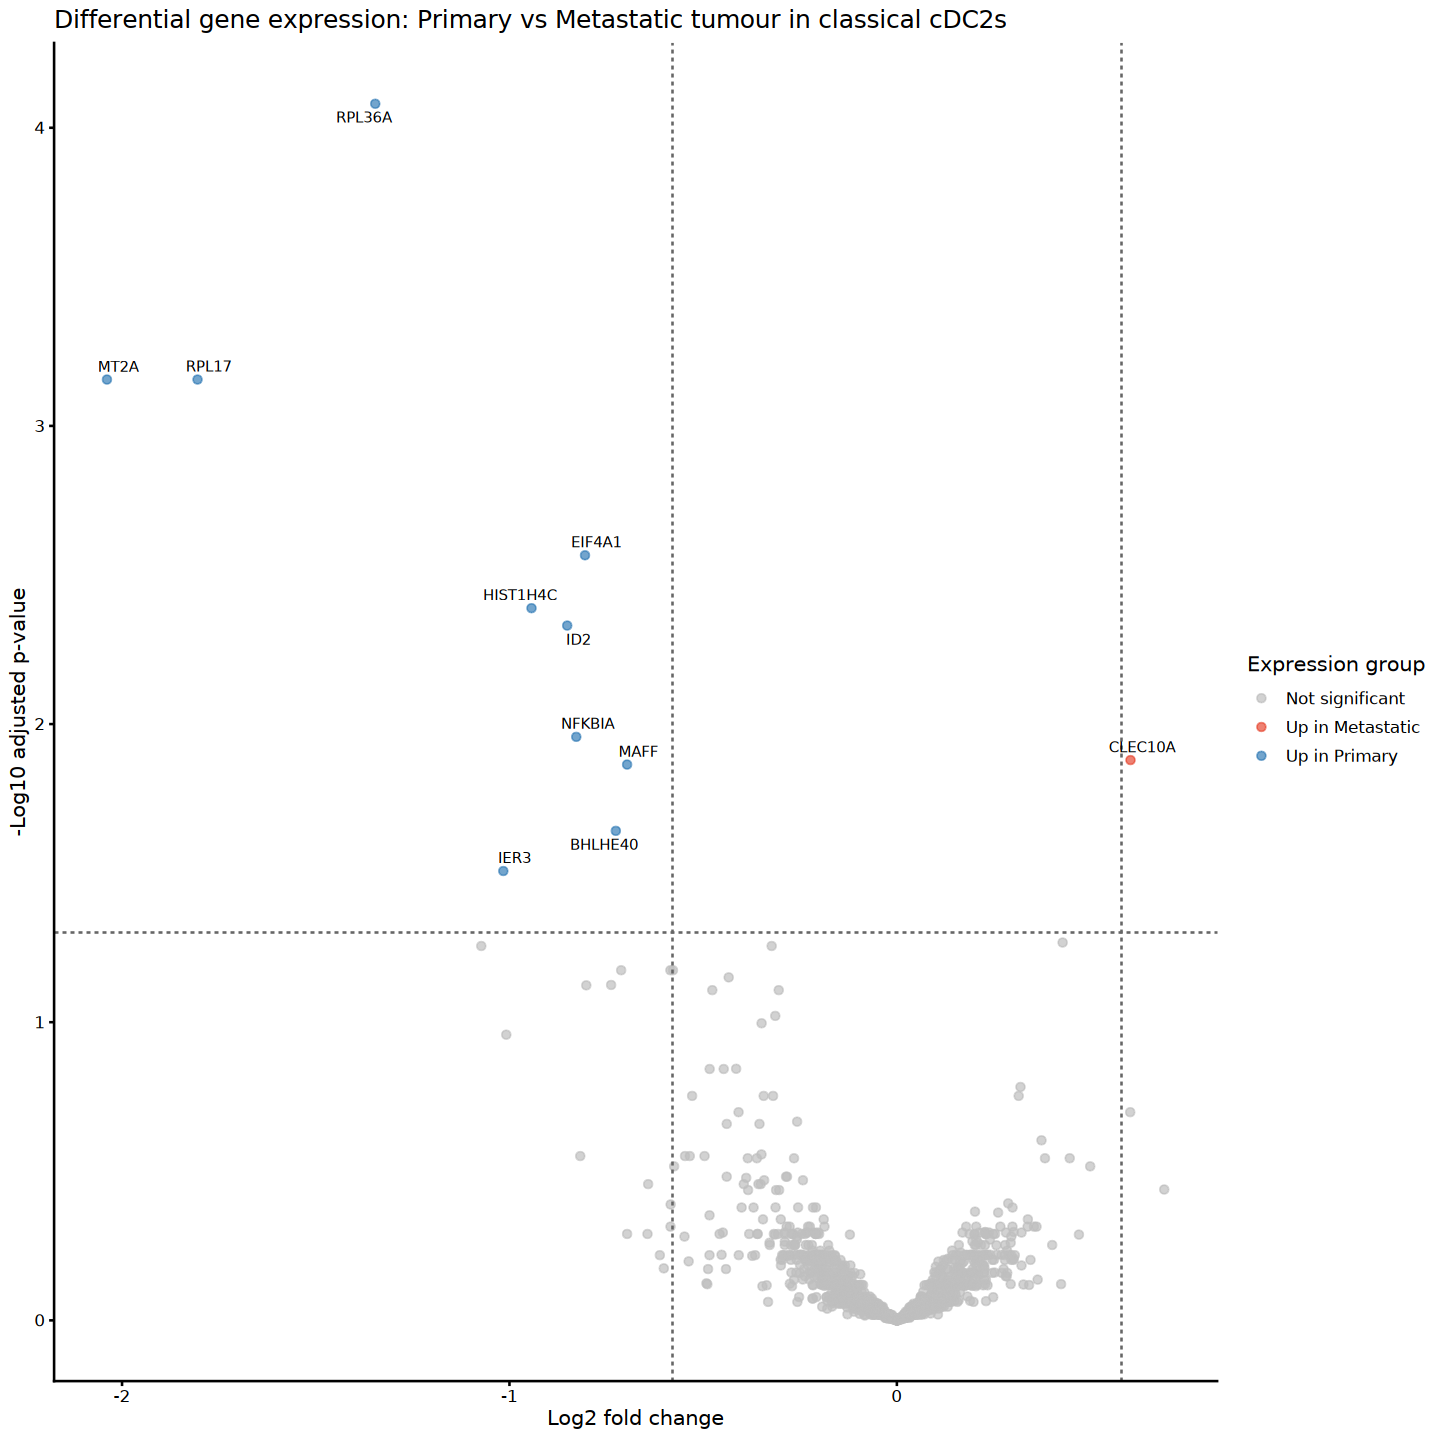

In [42]:
# Prepare plotting data
volcano_data <- results %>%
mutate(neg_log10_FDR = -log10(pmax(FDR, 1e-300)))

# Select genes to label
label_genes <- volcano_data %>%
  filter(DEG_status != "Not significant") %>%
  arrange(FDR) %>%
  slice_head(n = 15)

# Generate plot
ggplot(volcano_data, aes(x = logFC, y = neg_log10_FDR)) +
  geom_point(aes(colour = DEG_status), alpha = 0.7, size = 1.8) +
  geom_vline(xintercept = c(-logfc_cutoff, logfc_cutoff), linetype = "dashed", colour = "grey40") +
  geom_hline(yintercept = -log10(fdr_cutoff), linetype = "dashed", colour = "grey40") +
  geom_text_repel(data = label_genes, aes(label = Genes), size = 3, max.overlaps = 20) +
  scale_colour_manual(values = c(
      "Up in Primary" = "#377EB8",
      "Up in Metastatic" = "#E64B35",
      "Not significant" = "grey75")) +
  labs( title = paste( "Differential gene expression: Primary vs Metastatic tumour in classical cDC2s"),
    x = "Log2 fold change",
    y = "-Log10 adjusted p-value",
    colour = "Expression group") +
  theme_classic(base_size = 12)